# Evaluasi tiga model pada foto pribadi

NRP **5054241018**. Satu kali **Run all** mengevaluasi YOLO11s-seg, Mask R-CNN, dan RF-DETR Seg Small secara berurutan pada **359 gambar original test Roboflow** dan **56 foto pribadi**. Notebook memuat checkpoint terbaik yang sudah dilatih.

Pilih runtime GPU di Colab dan hubungkan Google Drive saat diminta. Seluruh path sudah diisi untuk folder proyek `MyDrive/Computer_Vision_Tugas_CPMK3`. Hasil masuk ke `outputs/artifacts/<model>/all_classes/eval_personal56/`, dan tabel bersama masuk ke `outputs/reports/all_classes/eval_personal56/`.

Sumber foto adalah `foto-sendiri/foto-sendiri-final/`. COCO final berada di `annotation-results/annotations.coco.json`. Notebook memeriksa 56 nama foto beserta metadata dan mencatat lampiran bukti yang masih kurang. Jika sesi terputus, jalankan lagi dengan label yang sama untuk melewati evaluasi model yang telah lengkap.


### 1.1 Registrasi cell

Simpan source cell yang diperlukan oleh proses inferensi terpisah.


In [1]:
CELL_REGISTRY = {}

def register_cell(cell_id, tag):
    shell = get_ipython()
    source = ""
    if getattr(shell, "kernel", None) is not None:
        source = shell.kernel.get_parent().get("content", {}).get("code", "")
    if not source:
        source = shell.history_manager.input_hist_raw[-1]
    lines = source.splitlines(keepends=True)
    expected = f"register_cell({cell_id!r}, {tag!r})"
    if not lines or lines[0].strip() != expected:
        raise RuntimeError("Source cell tidak sesuai. Jalankan notebook dengan cell terpisah.")
    CELL_REGISTRY[cell_id] = {"tag": tag, "source": "".join(lines[1:])}


### 1.2 Konfigurasi evaluasi

Tentukan sumber gambar, COCO, dan nama run evaluasi.


In [2]:
register_cell('cell-004', 'config')
MODE = "predict"
MODEL = "all"
MODEL_ORDER = ["yolo11", "maskrcnn", "rfdetr"]
RUNTIME = "colab"
DRIVE_PROJECT = "/content/drive/MyDrive/Computer_Vision_Tugas_CPMK3"
RAW_DATASET = f"{DRIVE_PROJECT}/dataset"
PERSONAL_DATASET = f"{DRIVE_PROJECT}/foto-sendiri/foto-sendiri-final"
PERSONAL_ANNOTATIONS = f"{DRIVE_PROJECT}/annotation-results/annotations.coco.json"
PERSONAL_METADATA = ""
EXPECTED_PERSONAL_IMAGES = 56
RUN_LABEL = "eval_personal56"
SCENARIO = "all_classes"
SMOKE_TEST = False
ENABLE_PERSONAL = True
SKIP_COMPLETED = True
SCORE_FLOOR = 0.001
MAX_DETECTIONS = 100


### 1.3 Checkpoint yang digunakan

Gunakan checkpoint terbaik dari run Colab untuk masing-masing model.


In [3]:
register_cell('cell-006', 'checkpoints')
CHECKPOINTS = {
    "yolo11": "artifacts/yolo11/all_classes/colab_quality01/best.pt",
    "maskrcnn": "artifacts/maskrcnn/all_classes/colab_quality02/best.pth",
    "rfdetr": "artifacts/rfdetr/all_classes/colab_quality01/best.pth",
}


### 1.4 Dependensi dasar

Siapkan PyCOCOTools untuk memeriksa mask dan menghitung AP.


In [4]:
register_cell('cell-008', 'base_install')
import sys
import subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pycocotools"])


0

### 1.5 Library dan runtime

Muat library untuk audit, inferensi, dan penyimpanan laporan.


In [5]:
register_cell('cell-010', 'base_imports')
import copy
import gzip
import hashlib
import importlib.metadata
import io
import json
import os
import shutil
import subprocess
import sys
import tempfile
import time
from collections import Counter, defaultdict
from contextlib import redirect_stdout
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

assert RUN_LABEL and all(c.isalnum() or c in "_-" for c in RUN_LABEL)
assert 0 <= SCORE_FLOOR < 1 and MAX_DETECTIONS == 100
assert len(MODEL_ORDER) == len(set(MODEL_ORDER)) and MODEL_ORDER


### 1.6 Google Drive dan output

Hubungkan Drive dan pisahkan salinan kerja dengan direktori laporan.


In [6]:
register_cell('cell-012', 'paths')
if RUNTIME not in {"colab", "local"}:
    raise ValueError('Pilih RUNTIME "colab" atau "local".')
IS_COLAB = RUNTIME == "colab"
if IS_COLAB:
    mount_root = Path("/content/drive")
    if not (mount_root / "MyDrive").is_dir():
        if "EXPECTED_DATASET_ID" in globals():
            raise RuntimeError("Hubungkan Google Drive dari notebook Colab sebelum menjalankan worker.")
        try:
            from google.colab import drive
        except ModuleNotFoundError as error:
            raise RuntimeError('Buka notebook di Google Colab atau ubah RUNTIME ke "local".') from error
        drive.mount(str(mount_root))
    project = Path(DRIVE_PROJECT)
    if not project.is_dir():
        raise FileNotFoundError(f"Folder proyek Drive tidak ditemukan: {project}")
    WORK = project / "outputs"
    PREPARED = Path("/content/cpmk3_workspace/prepared")
else:
    WORK = Path.cwd() / "outputs/cpmk3"
    PREPARED = WORK / "prepared"
report_label = RUN_LABEL + ("_smoke" if SMOKE_TEST else "")
REPORTS = WORK / "reports" / SCENARIO / report_label
for folder in (WORK, PREPARED, REPORTS):
    folder.mkdir(parents=True, exist_ok=True)
print("Direktori hasil:", WORK)


Mounted at /content/drive
Direktori hasil: /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/outputs


### 1.7 Penyimpanan JSON

Gunakan penulisan atomik untuk metadata dan status evaluasi.


In [7]:
register_cell('cell-014', 'json_utils')
def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def write_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_name(path.name + ".tmp")
    try:
        partial.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")
        os.replace(partial, path)
    finally:
        if partial.exists():
            partial.unlink()

def fingerprint(data):
    raw = json.dumps(data, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(raw).hexdigest()


## 2. Audit data


### 2.1 Sumber Roboflow

Buka anotasi dari tiga split asli agar fingerprint dapat dibandingkan dengan checkpoint.


In [8]:
register_cell('cell-017', 'discover')
def locate_dataset(path):
    folder = Path(path).expanduser().resolve()
    required = [folder / split / "_annotations.coco.json" for split in ("train", "valid", "test")]
    missing = [str(annotation) for annotation in required if not annotation.is_file()]
    if missing:
        raise FileNotFoundError("File anotasi COCO tidak ditemukan:\n- " + "\n- ".join(missing))
    return folder

worker_has_staged_data = "EXPECTED_DATASET_ID" in globals() and bool(globals().get("STAGED_DATASET"))
RAW = locate_dataset(STAGED_DATASET if worker_has_staged_data else RAW_DATASET)
raw_coco = {split: read_json(RAW / split / "_annotations.coco.json") for split in ("train", "valid", "test")}
print("Sumber dataset:", RAW)


Sumber dataset: /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/dataset


### 2.2 Salinan kerja

Salin dataset sumber ke disk runtime agar pembacaan gambar tidak berulang dari Drive.


In [9]:
register_cell('cell-019', 'stage_dataset')
import tempfile

def stage_coco(source, split_data, destination):
    for split, data in split_data.items():
        target = destination / split
        target.mkdir(parents=True, exist_ok=True)
        for item in data["images"]:
            name = item["file_name"]
            if not name or name in {".", ".."} or Path(name).name != name or "\\" in name:
                raise ValueError(f"Nama file dataset tidak valid: {name}")
            shutil.copy2(source / split / name, target / name)
        write_json(target / "_annotations.coco.json", data)

if IS_COLAB and not worker_has_staged_data:
    cache = Path(tempfile.mkdtemp(prefix="raw_", dir=PREPARED.parent))
    try:
        stage_coco(RAW, raw_coco, cache)
    except BaseException:
        shutil.rmtree(cache, ignore_errors=True)
        raise
    print("Salinan dataset Colab:", cache)
    RAW = cache
STAGED_DATASET = str(RAW) if IS_COLAB else ""


Salinan dataset Colab: /content/cpmk3_workspace/raw_k1nvpix_


### 2.3 Daftar kelas

Gunakan urutan kelas yang sama dengan training.


In [10]:
register_cell('cell-021', 'categories')
train_categories = raw_coco["train"]["categories"]
annotated_ids = {a["category_id"] for a in raw_coco["train"]["annotations"]}
parent_names = {c.get("supercategory") for c in train_categories}
categories = sorted([
    c for c in train_categories
    if not (c["name"] in parent_names and c["id"] not in annotated_ids
            and c.get("supercategory") != c["name"])
], key=lambda c: c["id"])
for split, data in raw_coco.items():
    assert data["categories"] == train_categories, f"Daftar kelas berbeda: {split}"
CLASS_IDS = [c["id"] for c in categories]
CLASS_NAMES = {c["id"]: c["name"] for c in categories}
SOURCE_ID = fingerprint(raw_coco)
print("Kelas segmentasi:", len(categories))


Kelas segmentasi: 74


### 2.4 Pemeriksaan COCO sumber

Periksa file gambar, koordinat polygon, dan hubungan antara gambar serta anotasi.


In [11]:
register_cell('cell-023', 'audit_function')
def audit_split(split, data, hashes):
    images = {i["id"]: i for i in data["images"]}
    assert len(images) == len(data["images"]), "ID gambar ganda"
    assert len({a["id"] for a in data["annotations"]}) == len(data["annotations"])
    problems, annotated = [], Counter()
    for item in data["images"]:
        path = RAW / split / item["file_name"]
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        hashes[digest].append(f"{split}/{item['file_name']}")
        with Image.open(path) as image:
            actual = image.size
            image.verify()
        if actual != (item["width"], item["height"]):
            problems.append({"split": split, "file_name": item["file_name"], "actual": actual})
    for ann in data["annotations"]:
        assert ann["image_id"] in images and ann["category_id"] in CLASS_IDS
        assert isinstance(ann["segmentation"], list) and ann["segmentation"]
        item = images[ann["image_id"]]
        for polygon in ann["segmentation"]:
            xy = np.asarray(polygon).reshape(-1, 2)
            assert len(xy) >= 3 and np.isfinite(xy).all()
            assert (xy >= 0).all() and (xy <= [item["width"], item["height"]]).all()
        annotated[ann["image_id"]] += 1
    return problems, len(set(images) - set(annotated))


### 2.5 Ringkasan dataset

Simpan ukuran split, distribusi kelas, dan hasil pemeriksaan duplikasi.


In [12]:
register_cell('cell-025', 'audit_run')
hashes = defaultdict(list)
audit_rows, size_issues, distribution = [], [], []
for split, data in raw_coco.items():
    issues, empty = audit_split(split, data, hashes)
    size_issues.extend(issues)
    audit_rows.append({"split": split, "images": len(data["images"]),
                       "annotations": len(data["annotations"]), "empty_images": empty})
    for category in categories:
        anns = [a for a in data["annotations"] if a["category_id"] == category["id"]]
        distribution.append({"split": split, "category_id": category["id"],
                             "name": category["name"], "instances": len(anns),
                             "images": len({a["image_id"] for a in anns})})
distribution = pd.DataFrame(distribution)
duplicates = [paths for paths in hashes.values() if len(paths) > 1]
SOURCE_ID = fingerprint({"annotations": raw_coco, "image_sha256": sorted(hashes)})
write_json(REPORTS / "audit.json", {"source_id": SOURCE_ID, "splits": audit_rows,
           "size_issues": size_issues, "exact_duplicates": duplicates})
distribution.to_csv(REPORTS / "class_distribution.csv", index=False)
display(pd.DataFrame(audit_rows))
display(pd.DataFrame(size_issues))
print("Kelompok duplikasi identik:", len(duplicates))
if any(len({p.split('/')[0] for p in group}) > 1 for group in duplicates):
    raise ValueError("Duplikasi lintas split perlu ditinjau sebelum training.")


,split,images,annotations,empty_images
0,train,397,4479,0
1,valid,166,2022,1
2,test,359,5344,0


,split,file_name,actual
0,train,182169107_jpg.rf.c9b1bbecf1474a5b36a6df197c30d...,"(480, 640)"
1,train,182169121_jpg.rf.eb0ccb71d0ea38adf1e38bf9c02a4...,"(480, 640)"
2,valid,182169109_jpg.rf.0531e60eb6e404d9633ed0c23a381...,"(480, 640)"
3,valid,182169108_jpg.rf.205d9f1ed8f888006b8f97fc29eb8...,"(480, 640)"


Kelompok duplikasi identik: 0


### 2.6 Format mask

Siapkan konversi polygon atau RLE serta daftar koreksi orientasi.


In [13]:
register_cell('cell-027', 'normalization_helpers')
ROTATE_CLOCKWISE = {
    "182169107_jpg.rf.c9b1bbecf1474a5b36a6df197c30dfed.jpg",
    "182169121_jpg.rf.eb0ccb71d0ea38adf1e38bf9c02a4a15.jpg",
    "182169109_jpg.rf.0531e60eb6e404d9633ed0c23a381fe7.jpg",
    "182169108_jpg.rf.205d9f1ed8f888006b8f97fc29eb8790.jpg",
}
unexpected = {row["file_name"] for row in size_issues} - ROTATE_CLOCKWISE
assert not unexpected, f"Masalah ukuran baru perlu diperiksa: {unexpected}"
corrections = []

def polygon_rle(segmentation, height, width):
    if isinstance(segmentation, dict):
        if list(segmentation.get("size", [])) != [height, width]:
            raise ValueError(f"Ukuran mask RLE berbeda dari gambar {width} × {height}.")
        counts = segmentation["counts"]
        return (mask_utils.frPyObjects(segmentation, height, width) if isinstance(counts, list)
                else {"size": [height, width], "counts": counts.encode("ascii")})
    return mask_utils.merge(mask_utils.frPyObjects(segmentation, height, width))

def mask_from_annotation(ann, image):
    rle = polygon_rle(ann["segmentation"], image["height"], image["width"])
    return mask_utils.decode(rle).astype(np.uint8)


### 2.7 Penyalinan foto

Salin gambar sesuai anotasi dan terapkan koreksi orientasi pada salinan Roboflow.


In [14]:
register_cell('cell-029', 'copy_images')
def copy_images(source_folder, output_folder, data, apply_rotation=False):
    output_folder.mkdir(parents=True, exist_ok=True)
    for item in data["images"]:
        name = item["file_name"]
        assert Path(name).name == name, "Nama file gambar harus tanpa subdirektori."
        source, target = source_folder / name, output_folder / name
        with Image.open(source) as image:
            mismatch = image.size != (item["width"], item["height"])
            if mismatch:
                assert apply_rotation and name in ROTATE_CLOCKWISE, name
                fixed = image.transpose(Image.Transpose.ROTATE_270)
                assert fixed.size == (item["width"], item["height"])
                fixed.convert("RGB").save(target, quality=100, subsampling=0)
                corrections.append({"file_name": name, "action": "rotate_90_clockwise"})
            elif not target.exists():
                shutil.copy2(source, target)


### 2.8 Normalisasi anotasi

Hitung ulang luas dan bounding box dari mask dan buat ID instance berurutan.


In [15]:
register_cell('cell-031', 'normalize_annotations')
def normalized_annotations(data, keep_ids):
    result = copy.deepcopy(data)
    result["categories"] = [copy.deepcopy(c) for c in categories if c["id"] in keep_ids]
    images = {i["id"]: i for i in data["images"]}
    result["annotations"] = []
    for ann in data["annotations"]:
        if ann["category_id"] not in keep_ids:
            continue
        item = images[ann["image_id"]]
        rle = polygon_rle(ann["segmentation"], item["height"], item["width"])
        assert mask_utils.area(rle) > 0, f"Mask kosong: {ann['id']}"
        row = copy.deepcopy(ann)
        row["id"] = len(result["annotations"]) + 1
        row["area"] = float(mask_utils.area(rle))
        row["bbox"] = mask_utils.toBbox(rle).tolist()
        row["iscrowd"] = int(ann.get("iscrowd", 0))
        result["annotations"].append(row)
    return result


### 2.9 Dataset evaluasi

Siapkan COCO dan hitung identitas dataset dengan cara yang sama seperti notebook training.


In [16]:
register_cell('cell-033', 'prepare_full')
PREPARED = PREPARED / SOURCE_ID
FULL_COCO = PREPARED / "coco_all"
full_coco = {}
for split, data in raw_coco.items():
    folder = FULL_COCO / split
    copy_images(RAW / split, folder, data, apply_rotation=True)
    full_coco[split] = normalized_annotations(data, CLASS_IDS)
    write_json(folder / "_annotations.coco.json", full_coco[split])
DATASET_ID = fingerprint({"source_id": SOURCE_ID, "normalized": full_coco})
if "EXPECTED_DATASET_ID" in globals():
    assert DATASET_ID == EXPECTED_DATASET_ID, "Dataset fingerprint worker berbeda dari parent."
write_json(REPORTS / "normalization.json", {
    "source_id": SOURCE_ID, "dataset_id": DATASET_ID,
    "corrections": corrections, "area": "rasterized_segmentation",
    "bbox": "rasterized_segmentation", "class_ids": CLASS_IDS,
})
print("Identitas dataset:", DATASET_ID)


Identitas dataset: efb3e74aa2cb0110c4d8a1ec86a5a3a522a02fa6ce27ad145c8bc15397b68863


### 2.10 Lokasi foto pribadi

Temukan foto dan file COCO final meskipun keduanya berada di folder berbeda.


In [17]:
register_cell('cell-035', 'personal_paths')
def locate_personal_dataset(image_root, annotation_path):
    folder = Path(image_root)
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder foto sendiri tidak ditemukan: {folder}")
    if annotation_path:
        annotation = Path(annotation_path)
        if not annotation.is_file():
            raise FileNotFoundError(f"File anotasi tidak ditemukan: {annotation}")
        return folder, annotation
    for candidate in (folder, folder / "test"):
        for filename in ("_annotations.coco.json", "annotations.coco.json"):
            annotation = candidate / filename
            if annotation.is_file():
                return candidate, annotation
    raise FileNotFoundError(f"Tidak ada file COCO di {folder} atau folder test. Isi PERSONAL_ANNOTATIONS.")


### 2.11 Audit foto pribadi

Cocokkan nama file, ukuran, kelas, dan mask dari paket COCO final.


In [18]:
register_cell('cell-037', 'personal_load')
def load_personal():
    if not ENABLE_PERSONAL:
        return None
    assert PERSONAL_DATASET, "Isi PERSONAL_DATASET dengan direktori foto sendiri."
    folder, annotation_file = locate_personal_dataset(PERSONAL_DATASET, PERSONAL_ANNOTATIONS)
    data = read_json(annotation_file)
    assert len(data["images"]) >= 40, "File COCO harus memuat minimal 40 foto sendiri."
    names = {item["file_name"] for item in data["images"]}
    image_ids = {item["id"] for item in data["images"]}
    assert len(names) == len(image_ids) == len(data["images"]), "Nama atau ID foto ganda pada COCO."
    disk_names = {p.name for p in folder.iterdir() if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}}
    if disk_names - names:
        print(f"Foto di folder tanpa entri COCO ({len(disk_names - names)}):", sorted(disk_names - names))
    names_to_id = {c["name"]: c["id"] for c in categories}
    own_categories = {c["id"]: c["name"] for c in data["categories"]}
    for ann in data["annotations"]:
        assert ann["image_id"] in image_ids, f"Anotasi merujuk ke ID gambar yang hilang: {ann['image_id']}"
        name = own_categories.get(ann["category_id"])
        assert name in names_to_id, f"Kelas foto sendiri tidak dikenal: {name or ann['category_id']}"
        ann["category_id"] = names_to_id[name]
    for item in data["images"]:
        name = item["file_name"]
        assert name and name not in {".", ".."} and Path(name).name == name and "\\" not in name, name
        with Image.open(folder / name) as image:
            expected = (item["width"], item["height"])
            assert image.size == expected, f"Ukuran {name}: gambar {image.size}, anotasi {expected}."
    assert data["annotations"], "File COCO belum memiliki mask."
    normalized = normalized_annotations(data, CLASS_IDS)
    destination = Path(tempfile.mkdtemp(prefix="personal_", dir=PREPARED))
    copy_images(folder, destination, normalized)
    write_json(destination / "_annotations.coco.json", normalized)
    images_with_masks = {a["image_id"] for a in normalized["annotations"]}
    print(f"COCO foto sendiri: {annotation_file}")
    print(f"{len(names)} foto tercatat, {len(images_with_masks)} berisi mask, {len(normalized['annotations'])} instance.")
    return folder, destination, normalized


### 2.12 Metadata dan bukti

Periksa jumlah foto sulit dan catat ketersediaan EXIF serta screenshot anotasi.


In [20]:
register_cell('cell-039', 'personal_evidence')
def check_personal_evidence(folder, data, path):
    metadata = pd.read_csv(path, keep_default_na=False)
    required = {"file_name", "is_difficult", "condition", "exif_proof"}
    assert required <= set(metadata), f"Kolom CSV wajib: {required}"
    assert metadata["file_name"].is_unique, "Nama foto ganda pada CSV."
    names = {item["file_name"] for item in data["images"]}
    listed = set(metadata["file_name"])
    assert listed == names, f"Nama CSV dan COCO berbeda. Kurang: {sorted(names - listed)}. Berlebih: {sorted(listed - names)}."
    flags = metadata["is_difficult"].astype(str).str.strip().str.lower()
    difficult = flags.isin(["1", "true", "yes", "ya"])
    assert difficult.sum() >= 10, "Minimal 10 foto harus dalam kondisi sulit."
    assert metadata.loc[difficult, "condition"].str.strip().ne("").all(), "Alasan foto sulit belum lengkap."
    roots = {path.parent, folder}
    missing_exif = [row.file_name for row in metadata.itertuples()
                    if not row.exif_proof or not any((root / row.exif_proof).is_file() for root in roots)]
    screenshots = {p.resolve() for root in roots for p in (root / "annotation_screenshots").rglob("*") if p.is_file()}
    report = {"photos": len(names), "difficult_photos": int(difficult.sum()),
              "metadata_csv": str(path), "exif_missing": missing_exif, "annotation_screenshots": len(screenshots)}
    metadata.to_csv(REPORTS / "personal_photo_metadata.csv", index=False)
    write_json(REPORTS / "personal_evidence_status.json", report)
    print(f"Foto sulit: {difficult.sum()}/{len(names)}. Bukti EXIF hilang: {len(missing_exif)}. Screenshot anotasi: {len(screenshots)}.")
    return metadata

personal = load_personal()
if personal is not None:
    folder, _, photo_data = personal
    candidates = [folder / name for name in ("photo_metadata_56.csv", "photo_metadata.csv")]
    if PERSONAL_ANNOTATIONS:
        candidates.append(Path(PERSONAL_ANNOTATIONS).parent / "photo_metadata_56.csv")
    metadata_path = (Path(PERSONAL_METADATA) if PERSONAL_METADATA else
                     next((path for path in candidates if path.is_file()), candidates[0]))
    if metadata_path.is_file():
        personal_metadata = check_personal_evidence(folder, photo_data, metadata_path)
    elif MODE == "prepare":
        print(f"Audit foto dan COCO selesai. Metadata belum tersedia: {metadata_path}")
    else:
        raise FileNotFoundError(f"Metadata foto tidak ditemukan: {metadata_path}. Isi PERSONAL_METADATA.")
else:
    print("Bagian foto HP dilewati. Fokus tahap ini: dataset Roboflow dan tiga model.")


COCO foto sendiri: /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/annotation-results/annotations.coco.json
56 foto tercatat, 56 berisi mask, 499 instance.
Foto sulit: 17/56. Bukti EXIF hilang: 56. Screenshot anotasi: 0.


### 2.13 Identitas paket evaluasi

Catat versi foto dan mask agar hasil selalu merujuk pada paket yang sama.


In [21]:
register_cell('cell-041', 'prepared_inputs')
assert personal is not None and len(personal[2]["images"]) == EXPECTED_PERSONAL_IMAGES, "COCO final harus memuat 56 foto."
assert len(full_coco["test"]["images"]) == 359, "Gunakan original test Roboflow dengan 359 gambar."
personal_hashes = {item["file_name"]: hashlib.sha256((personal[1] / item["file_name"]).read_bytes()).hexdigest()
                   for item in personal[2]["images"]}
if "sha256" in personal_metadata:
    declared = dict(zip(personal_metadata["file_name"], personal_metadata["sha256"]))
    assert personal_hashes == declared, "Isi foto berbeda dari manifest seleksi."
PERSONAL_ID = fingerprint({"annotations": personal[2], "images": personal_hashes})
write_json(REPORTS / "dataset_manifest.json", {"roboflow_dataset_id": DATASET_ID,
           "personal_dataset_id": PERSONAL_ID, "original_test_images": 359,
           "personal_test_images": len(personal[2]["images"]), "personal_image_sha256": personal_hashes})


## 3. Inferensi dan metrik


### 3.1 Setup model

Setiap worker memuat dependensi model dan mencatat perangkat yang dipakai.


In [22]:
register_cell('cell-044', 'worker_setup')
needs_model = MODEL != "all"
if needs_model:
    requirements = {"yolo11": "ultralytics==8.4.215", "rfdetr": "rfdetr[train]==1.12.1"}
    if MODEL in requirements:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", requirements[MODEL]])
    import torch
    import torchvision
    import torchvision.transforms.functional as TF
    if not torch.cuda.is_available():
        raise RuntimeError("Pilih runtime GPU di Colab untuk menjalankan inferensi.")
    DEVICE = "cuda"
    RUN_DIR = Path(ARTIFACT_DIR)
    CHECKPOINT = Path(CHECKPOINT_PATH)
    ACTIVE_IDS = RUN_CONFIG["category_ids"]
    CLASS_NAMES = {int(cid): name for cid, name in CATEGORY_NAMES.items()}
    INDEX_TO_ID = dict(enumerate(ACTIVE_IDS))
    if MODEL == "yolo11":
        YOLO_SIZE = RUN_CONFIG["resolution"][MODEL]
    elif MODEL == "maskrcnn":
        MASKRCNN_SHORT, MASKRCNN_LONG = RUN_CONFIG["resolution"][MODEL]
    device_info = {"gpu": torch.cuda.get_device_name(0), "torch": torch.__version__,
                   "torchvision": torchvision.__version__, "python": sys.version,
                   "model": MODEL, "checkpoint": str(CHECKPOINT)}
    print(device_info)
    write_json(RUN_DIR / "environment_predict.json", device_info)
    predict_one = None


### 3.2 Format prediksi

Simpan mask prediksi dalam COCO RLE terkompresi.


In [23]:
register_cell('cell-046', 'prediction_format')
def prediction_record(image_id, category_id, score, binary_mask):
    rle = mask_utils.encode(np.asfortranarray(binary_mask.astype(np.uint8)))
    rle["counts"] = rle["counts"].decode("ascii")
    return {"image_id": int(image_id), "category_id": int(category_id),
            "score": float(score), "segmentation": rle}

def write_predictions(path, predictions):
    with gzip.open(path, "wt", encoding="utf-8") as handle:
        json.dump(predictions, handle)

def read_predictions(path):
    with gzip.open(path, "rt", encoding="utf-8") as handle:
        return json.load(handle)

def make_coco(data):
    coco = COCO()
    coco.dataset = copy.deepcopy(data)
    with redirect_stdout(io.StringIO()):
        coco.createIndex()
    return coco


### 3.3 COCO Mask AP

Hitung AP, AR, serta metrik per kelas dengan protokol yang sama untuk ketiga model.


In [24]:
register_cell('cell-048', 'evaluator')
def evaluate_predictions(data, predictions, category_ids=None):
    gt = make_coco(data)
    with redirect_stdout(io.StringIO()):
        dt = gt.loadRes(copy.deepcopy(predictions)) if predictions else make_coco({
            "images": data["images"], "categories": data["categories"], "annotations": []})
        evaluator = COCOeval(gt, dt, "segm")
        evaluator.params.catIds = sorted(category_ids or [c["id"] for c in data["categories"]])
        evaluator.params.maxDets = [1, 10, MAX_DETECTIONS]
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    rows = []
    precision = evaluator.eval["precision"]
    for index, cid in enumerate(evaluator.params.catIds):
        values = precision[:, :, index, 0, -1]
        valid = values[values >= 0]
        values50 = precision[0, :, index, 0, -1]
        rows.append({"category_id": cid, "name": CLASS_NAMES[cid],
                     "gt_instances": sum(a["category_id"] == cid for a in data["annotations"]),
                     "gt_images": len({a["image_id"] for a in data["annotations"] if a["category_id"] == cid}),
                     "mask_ap": float(valid.mean()) if len(valid) else None,
                     "mask_ap50": float(values50[values50 >= 0].mean()) if (values50 >= 0).any() else None})
    summary = {"mask_ap": float(evaluator.stats[0]), "mask_ap50": float(evaluator.stats[1]),
               "mask_ap75": float(evaluator.stats[2]), "mask_ar100": float(evaluator.stats[8]),
               "mask_ap_small": float(evaluator.stats[3]), "mask_ap_medium": float(evaluator.stats[4]),
               "mask_ap_large": float(evaluator.stats[5])}
    return summary, pd.DataFrame(rows)


### 3.4 YOLO11s-seg

Muat bobot YOLO11s-seg dan cocokkan urutan kelas dengan checkpoint.


In [25]:
register_cell('cell-050', 'yolo_load')
if needs_model and MODEL == "yolo11":
    from ultralytics import YOLO
    yolo_model = YOLO(str(CHECKPOINT))
    expected_names = [CLASS_NAMES[cid] for cid in ACTIVE_IDS]
    assert [yolo_model.names[i] for i in range(len(expected_names))] == expected_names, "Urutan kelas YOLO berbeda."


### 3.5 Adapter YOLO11

Konversi indeks YOLO ke ID kategori COCO dan kembalikan mask ke ukuran foto.


In [26]:
register_cell('cell-052', 'yolo_predictor')
def predict_yolo(image):
    result = yolo_model.predict(image, imgsz=YOLO_SIZE, conf=SCORE_FLOOR,
                                max_det=MAX_DETECTIONS, retina_masks=True,
                                device=0 if DEVICE == "cuda" else "cpu", verbose=False)[0]
    if result.masks is None:
        return []
    rows = []
    for label, score, mask in zip(result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy(),
                                   result.masks.data.cpu().numpy()):
        binary = Image.fromarray((mask > 0.5).astype(np.uint8))
        binary = np.asarray(binary.resize(image.size, Image.Resampling.NEAREST))
        rows.append((INDEX_TO_ID[int(label)], float(score), binary))
    return rows

if needs_model and MODEL == "yolo11":
    predict_one = predict_yolo


### 3.6 Mask R-CNN

Bangun arsitektur Mask R-CNN yang cocok dengan bobot hasil training.


In [27]:
register_cell('cell-054', 'mask_model')
def build_maskrcnn(pretrained=True):
    from torchvision.models.detection import MaskRCNN, maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
    from torchvision.models.detection.backbone_utils import resnet_fpn_backbone
    from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
    from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
    from torchvision.ops import FrozenBatchNorm2d
    options = dict(min_size=MASKRCNN_SHORT, max_size=MASKRCNN_LONG,
                   box_score_thresh=SCORE_FLOOR, box_detections_per_img=MAX_DETECTIONS)
    if pretrained:
        model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT,
                                     weights_backbone=None, **options)
    else:
        backbone = resnet_fpn_backbone(backbone_name="resnet50", weights=None,
                                       norm_layer=FrozenBatchNorm2d, trainable_layers=3)
        model = MaskRCNN(backbone, num_classes=91, **options)
        for layer in model.modules():
            if isinstance(layer, FrozenBatchNorm2d):
                layer.eps = 0.0
    features = model.roi_heads.box_predictor.cls_score.in_features
    channels = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.box_predictor = FastRCNNPredictor(features, len(ACTIVE_IDS) + 1)
    model.roi_heads.mask_predictor = MaskRCNNPredictor(channels, 256, len(ACTIVE_IDS) + 1)
    return model.to(DEVICE)

if needs_model and MODEL == "maskrcnn":
    mask_model = build_maskrcnn(pretrained=False)


### 3.7 Adapter Mask R-CNN

Jalankan prediksi mask dan kumpulkan prediksi untuk satu split.


In [28]:
register_cell('cell-056', 'mask_predictor')
def predict_maskrcnn(image):
    mask_model.eval()
    with torch.inference_mode():
        result = mask_model([TF.to_tensor(image).to(DEVICE)])[0]
    rows = []
    for label, score, mask in zip(result["labels"].cpu().numpy(), result["scores"].cpu().numpy(),
                                   result["masks"][:, 0].cpu().numpy()):
        if score >= SCORE_FLOOR:
            rows.append((INDEX_TO_ID[int(label) - 1], float(score), (mask >= 0.5).astype(np.uint8)))
    return rows

def predict_dataset(folder, data, predictor, brightness=None):
    predictions = []
    for position, item in enumerate(data["images"]):
        with Image.open(Path(folder) / item["file_name"]) as source:
            image = source.convert("RGB")
        if brightness is not None:
            image = ImageEnhance.Brightness(image).enhance(brightness)
        for cid, score, mask in predictor(image):
            assert mask.shape == (item["height"], item["width"]), "Ukuran mask prediksi tidak sesuai."
            predictions.append(prediction_record(item["id"], cid, score, mask))
        if (position + 1) % 50 == 0:
            print(f"Inferensi {position + 1}/{len(data['images'])}")
    return predictions


### 3.8 Checkpoint Mask R-CNN

Pasangkan bobot dengan arsitektur, lalu aktifkan mode evaluasi.


In [29]:
register_cell('cell-058', 'mask_load')
if needs_model and MODEL == "maskrcnn":
    state = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
    mask_model.load_state_dict(state["model"])
    mask_model.eval()
    predict_one = predict_maskrcnn


### 3.9 Checkpoint RF-DETR

Muat RF-DETR Seg Small dan cocokkan urutan kelasnya.


In [30]:
register_cell('cell-060', 'rf_load')
if needs_model and MODEL == "rfdetr":
    from rfdetr import RFDETR
    rf_model = RFDETR.from_checkpoint(str(CHECKPOINT), device=DEVICE)
    assert list(rf_model.class_names) == [CLASS_NAMES[cid] for cid in ACTIVE_IDS], "Urutan kelas RF-DETR berbeda."


### 3.10 Adapter RF-DETR

Saring slot background dan ubah indeks kelas menjadi ID COCO.


In [31]:
register_cell('cell-062', 'rf_predictor')
def predict_rfdetr(image):
    detections = rf_model.predict(image, threshold=SCORE_FLOOR)
    if detections.mask is None:
        return []
    labels = np.asarray(detections.class_id)
    scores = np.asarray(detections.confidence)
    if labels.ndim != 1 or scores.shape != labels.shape or len(detections.mask) != len(labels):
        raise ValueError("Dimensi output RF-DETR tidak konsisten.")
    if not np.isfinite(scores).all():
        raise FloatingPointError("Confidence RF-DETR mengandung NaN/Inf.")
    background = len(ACTIVE_IDS)
    unknown = set(labels.tolist()) - set(INDEX_TO_ID) - {background}
    if unknown:
        raise ValueError(f"Class ID RF-DETR tidak dikenal: {sorted(unknown)}")
    foreground = np.flatnonzero(labels != background)
    order = foreground[np.argsort(-scores[foreground], kind="stable")][:MAX_DETECTIONS]
    return [(INDEX_TO_ID[int(labels[j])], float(scores[j]),
             np.asarray(detections.mask[j], dtype=np.uint8)) for j in order]

if needs_model and MODEL == "rfdetr":
    predict_one = predict_rfdetr


### 3.11 Ekspor prediksi dan metrik

Simpan hasil per split dan metrik per kelas.


In [32]:
register_cell('cell-064', 'save_metrics')
def save_evaluation(split, dataset, predictions):
    summary, per_class = evaluate_predictions(dataset, predictions, ACTIVE_IDS)
    write_predictions(RUN_DIR / f"predictions_{split}.json.gz", predictions)
    per_class.to_csv(RUN_DIR / f"per_class_{split}.csv", index=False)
    record = {**RUN_CONFIG, **summary, "split": split, "scope": "active",
              "images": len(dataset["images"]), "checkpoint": str(CHECKPOINT),
              "classes_with_ground_truth": int((per_class["gt_instances"] > 0).sum())}
    if split == "personal":
        record["personal_dataset_id"] = PERSONAL_ID
    write_json(RUN_DIR / f"metrics_{split}.json", record)
    display(pd.DataFrame([record])[['model_name', 'split', 'images', 'mask_ap', 'mask_ap50', 'mask_ar100']])


### 3.12 Evaluasi kedua test set

Jalankan inferensi dataset asal dan foto pribadi dari worker yang sama.


In [33]:
register_cell('cell-066', 'evaluate_parts')
if needs_model:
    assert predict_one is not None, f"Adapter prediksi belum dipilih untuk {MODEL}."
    started = time.perf_counter()
    splits = {"test": Path(ORIGINAL_TEST_DIR), "personal": Path(PERSONAL_TEST_DIR)}
    for split, folder in splits.items():
        part_start = time.perf_counter()
        data = read_json(folder / "_annotations.coco.json")
        print(f"Evaluasi {split}: {len(data['images'])} foto", flush=True)
        predictions = predict_dataset(folder, data, predict_one)
        save_evaluation(split, data, predictions)
        print(f"Evaluasi {split} selesai dalam {time.perf_counter() - part_start:.1f} detik.", flush=True)
    write_json(RUN_DIR / "evaluation_time.json", {"seconds": time.perf_counter() - started})


## 4. Jalankan ketiga model


### 4.1 Pemeriksaan checkpoint

Tampilkan lokasi dan konfigurasi checkpoint yang cocok dengan dataset.


In [34]:
register_cell('cell-069', 'validate_checkpoints')
def describe_checkpoint(model):
    checkpoint = (WORK / CHECKPOINTS[model]).resolve()
    if not checkpoint.is_file():
        raise FileNotFoundError(f"Checkpoint {model} tidak ditemukan: {checkpoint}")
    metadata_file = checkpoint.parent / "run_config.json"
    if not metadata_file.is_file():
        raise FileNotFoundError(f"Konfigurasi checkpoint {model} tidak ditemukan: {metadata_file}")
    config = read_json(metadata_file)
    expected = {"model": model, "scenario": SCENARIO, "dataset_id": DATASET_ID,
                "category_ids": CLASS_IDS, "smoke_test": False}
    for key, value in expected.items():
        if config.get(key) != value:
            raise ValueError(f"Checkpoint {model} berbeda pada {key}: {checkpoint}")
    print(model, config["run_label"], checkpoint)
    return checkpoint, config


### 4.2 Source proses inferensi

Kumpulkan sel inferensi untuk dijalankan pada virtual environment per model.


In [35]:
register_cell('cell-071', 'worker_sources')
WORKER_TAGS = ("base_imports", "json_utils", "worker_setup", "prediction_format", "evaluator",
               "yolo_load", "yolo_predictor", "mask_model", "mask_predictor", "mask_load",
               "rf_load", "rf_predictor", "save_metrics", "evaluate_parts")
by_tag = {item["tag"]: item["source"].rstrip() for item in CELL_REGISTRY.values()}
missing_tags = set(WORKER_TAGS) - set(by_tag)
assert not missing_tags, f"Jalankan Run all dari awal. Cell belum siap: {sorted(missing_tags)}"
WORKER_SOURCES = [by_tag[tag] for tag in WORKER_TAGS]
WORKER_SOURCE_ID = fingerprint(WORKER_SOURCES)
REQUIRED_FILES = [filename for split in ("test", "personal") for filename in
                  (f"metrics_{split}.json", f"per_class_{split}.csv", f"predictions_{split}.json.gz")]
REQUIRED_FILES.append("evaluation_time.json")


### 4.3 Virtual environment

Gunakan environment terpisah untuk YOLO, Mask R-CNN, dan RF-DETR.


In [36]:
register_cell('cell-073', 'sequence_environment')
import tempfile
import venv
import site

def model_python(model):
    folder = Path(tempfile.gettempdir()) / "cpmk3-model-envs" / model
    executable = folder / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
    venv.EnvBuilder(with_pip=False, system_site_packages=True).create(folder)
    command = [str(executable), "-c", "import sysconfig; print(sysconfig.get_path('purelib'))"]
    query = subprocess.run(command, capture_output=True, text=True)
    if query.returncode:
        raise RuntimeError(f"Worker Python gagal ({model}): {query.stderr.strip() or query.stdout.strip()}")
    packages = Path(query.stdout.strip())
    parents = list(dict.fromkeys(site.getsitepackages() + [
        path for path in sys.path if path.endswith(("site-packages", "dist-packages"))]))
    (packages / "runtime_parent.pth").write_text("\n".join(parents), encoding="utf-8")
    pip_check = subprocess.run([str(executable), "-m", "pip", "--version"], capture_output=True, text=True)
    if pip_check.returncode:
        raise RuntimeError(f"Worker pip gagal ({model}): {pip_check.stderr.strip() or pip_check.stdout.strip()}")
    return executable


### 4.4 Interupsi proses

Hentikan worker dengan tertib bila evaluasi diinterupsi.


In [37]:
register_cell('cell-075', 'sequence_interrupt')
import signal

def interrupt_worker(process):
    if process.poll() is not None:
        return
    if os.name == "posix":
        os.killpg(process.pid, signal.SIGINT)
    else:
        process.send_signal(signal.CTRL_BREAK_EVENT)
    try:
        process.wait(timeout=60)
    except subprocess.TimeoutExpired:
        process.terminate()
        try:
            process.wait(timeout=15)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait()


### 4.5 Console log

Tampilkan progres dan simpan log lengkap untuk setiap model.


In [38]:
register_cell('cell-077', 'sequence_process')
def execute_worker(python, script, config_path, folder):
    environment = dict(os.environ, PYTHONUNBUFFERED="1", MPLBACKEND="Agg")
    options = {"start_new_session": True} if os.name == "posix" else {
        "creationflags": subprocess.CREATE_NEW_PROCESS_GROUP}
    with (folder / "console_log.txt").open("a", encoding="utf-8") as log:
        process = subprocess.Popen([str(python), "-u", str(script), str(config_path)],
                                   stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                   text=True, encoding="utf-8", errors="replace", env=environment, **options)
        last_display, context_lines = 0.0, 0
        try:
            for line in process.stdout:
                log.write(line)
                log.flush()
                context_lines = max(0, context_lines - 1)
                if any(word in line for word in ["Traceback", "dependency conflicts", "Overall Metrics"]):
                    context_lines = 25
                important = any(word in line for word in ["Error", "error", "WARNING", "Warning", "checkpoint", "mask_ap"])
                if context_lines or important or time.monotonic() - last_display >= 5:
                    print(line.rstrip(), flush=True)
                    last_display = time.monotonic()
            return process.wait()
        except BaseException:
            interrupt_worker(process)
            raise
        finally:
            process.stdout.close()


### 4.6 Konfigurasi worker

Catat checkpoint sumber, identitas data, dan protokol evaluasi.


In [39]:
register_cell('cell-079', 'worker_config')
def make_evaluation_config(model, checkpoint, trained, folder):
    assert folder.resolve() != checkpoint.parent, "Gunakan RUN_LABEL yang berbeda dari label training."
    config = {**trained, "source_run_label": trained["run_label"], "run_label": RUN_LABEL,
              "score_floor": SCORE_FLOOR, "max_detections": MAX_DETECTIONS}
    worker = {"RUN_LABEL": RUN_LABEL, "MODEL": model, "MODEL_ORDER": MODEL_ORDER,
              "ARTIFACT_DIR": str(folder), "CHECKPOINT_PATH": str(checkpoint), "RUN_CONFIG": config,
              "SCORE_FLOOR": SCORE_FLOOR, "MAX_DETECTIONS": MAX_DETECTIONS, "CATEGORY_NAMES": CLASS_NAMES,
              "PERSONAL_ID": PERSONAL_ID, "ORIGINAL_TEST_DIR": str(FULL_COCO / "test"),
              "PERSONAL_TEST_DIR": str(personal[1])}
    stat = checkpoint.stat()
    signature = fingerprint({"run": config, "checkpoint": str(checkpoint), "mtime_ns": stat.st_mtime_ns,
                             "bytes": stat.st_size, "personal_id": PERSONAL_ID, "source_id": WORKER_SOURCE_ID})
    return worker, signature


### 4.7 Script worker

Bangun script inferensi dan tandai selesai setelah semua file hasil tersedia.


In [40]:
register_cell('cell-081', 'worker_writer')
def write_evaluation_worker(config, signature, folder):
    config_path = folder / "worker_config.json"
    script = folder / "worker.py"
    write_json(config_path, config)
    header = (
        "import json, os, sys\nfrom pathlib import Path\n"
        "os.environ['MPLBACKEND'] = 'Agg'\n"
        "globals().update(json.loads(Path(sys.argv[1]).read_text(encoding='utf-8')))\n"
        "def display(value):\n    print(value.to_string(index=False))\n"
    )
    footer = (
        f"\nrequired = {REQUIRED_FILES!r}\n"
        "assert all((RUN_DIR / name).is_file() and (RUN_DIR / name).stat().st_size > 0 for name in required)\n"
        f"write_json(RUN_DIR / 'completion.json', {{'signature': {signature!r}, 'status': 'completed'}})\n"
    )
    script.write_text(header + "\n\n".join(WORKER_SOURCES) + footer, encoding="utf-8")
    return script, config_path


### 4.8 Evaluasi per model

Gunakan kembali hasil lengkap yang cocok dengan checkpoint dan paket data saat ini.


In [41]:
register_cell('cell-083', 'run_model')
def run_model_evaluation(model):
    checkpoint, trained = describe_checkpoint(model)
    folder = WORK / "artifacts" / model / SCENARIO / RUN_LABEL
    config, signature = make_evaluation_config(model, checkpoint, trained, folder)
    folder.mkdir(parents=True, exist_ok=True)
    marker = folder / "completion.json"
    previous = read_json(marker) if marker.exists() else {}
    complete = previous.get("signature") == signature and previous.get("status") == "completed"
    complete = complete and all((folder / name).is_file() and (folder / name).stat().st_size > 0
                                for name in REQUIRED_FILES)
    if SKIP_COMPLETED and complete:
        return {"model": model, "status": "skipped", "artifact_dir": str(folder)}
    write_json(marker, {"signature": signature, "status": "running"})
    write_json(folder / "run_config.json", config["RUN_CONFIG"])
    script, settings = write_evaluation_worker(config, signature, folder)
    result = execute_worker(model_python(model), script, settings, folder)
    written = read_json(marker)
    if result != 0 or written != {"signature": signature, "status": "completed"}:
        raise RuntimeError(f"Evaluasi {model} gagal. Buka {folder / 'console_log.txt'}")
    return {"model": model, "status": "completed", "artifact_dir": str(folder)}


### 4.9 Evaluasi berurutan

Simpan status tiap worker agar progres dapat diperiksa dari Drive.


In [42]:
register_cell('cell-085', 'run_sequence')
evaluation_status = []
for model in MODEL_ORDER:
    started = time.perf_counter()
    print(f"Memulai evaluasi {model}", flush=True)
    try:
        row = run_model_evaluation(model)
    except KeyboardInterrupt:
        row = {"model": model, "status": "interrupted"}
        evaluation_status.append(row)
        write_json(REPORTS / "sequence_status.json", evaluation_status)
        raise
    except Exception as error:
        row = {"model": model, "status": "failed", "error": str(error)}
        print(row["error"], flush=True)
    row["seconds"] = time.perf_counter() - started
    evaluation_status.append(row)
    write_json(REPORTS / "sequence_status.json", evaluation_status)
display(pd.DataFrame(evaluation_status))


Memulai evaluasi yolo11
yolo11 colab_quality01 /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/outputs/artifacts/yolo11/all_classes/colab_quality01/best.pt
{'gpu': 'Tesla T4', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]', 'model': 'yolo11', 'checkpoint': '/content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/outputs/artifacts/yolo11/all_classes/colab_quality01/best.pt'}
Evaluasi test: 359 foto
Inferensi 50/359
Inferensi 100/359
Inferensi 150/359
Inferensi 200/359
Inferensi 250/359
Inferensi 300/359
Inferensi 350/359
 model_name split  images  mask_ap  mask_ap50  mask_ar100
Inferensi 50/56
 model_name    split  images  mask_ap  mask_ap50  mask_ar100
Memulai evaluasi maskrcnn
maskrcnn colab_quality02 /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/outputs/artifacts/maskrcnn/all_classes/colab_quality02/best.pth
{'gpu': 'Tesla T4', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'python': '3.13.16 (main, O

,model,status,artifact_dir,seconds
0,yolo11,completed,/content/drive/MyDrive/Computer_Vision_Tugas_C...,180.538552
1,maskrcnn,completed,/content/drive/MyDrive/Computer_Vision_Tugas_C...,277.216926
2,rfdetr,completed,/content/drive/MyDrive/Computer_Vision_Tugas_C...,150.792095


## 5. Membaca hasil


### 5.1 Tabel dan perubahan performa

Gabungkan hasil dua test set dan hitung perubahan Mask AP dalam poin.


,model_name,source_run_label,split,images,classes_with_ground_truth,mask_ap,mask_ap50,mask_ar100
0,YOLO11s-seg,colab_quality01,test,359,69,0.110445,0.172298,0.236875
1,YOLO11s-seg,colab_quality01,personal,56,39,0.148353,0.214900,0.240418
2,Mask R-CNN ResNet-50 FPN,colab_quality02,test,359,69,0.076525,0.131450,0.220512
3,Mask R-CNN ResNet-50 FPN,colab_quality02,personal,56,39,0.126661,0.175646,0.288117
4,RF-DETR Seg Small,colab_quality01,test,359,69,0.190810,0.274375,0.395567
5,RF-DETR Seg Small,colab_quality01,personal,56,39,0.300989,0.368994,0.456339


split,original_test_ap,personal_test_ap,personal_minus_original_ap_points
model_name,,,
Mask R-CNN ResNet-50 FPN,7.65,12.67,5.01
RF-DETR Seg Small,19.08,30.10,11.02
YOLO11s-seg,11.04,14.84,3.79


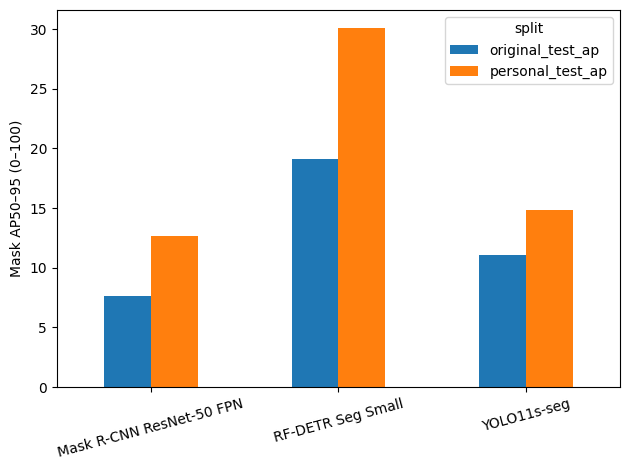

Laporan: /content/drive/MyDrive/Computer_Vision_Tugas_CPMK3/outputs/reports/all_classes/eval_personal56


In [43]:
register_cell('cell-088', 'report')
rows = [read_json(Path(job["artifact_dir"]) / f"metrics_{split}.json")
        for job in evaluation_status if job["status"] in {"completed", "skipped"}
        for split in ("test", "personal")]
if not rows:
    raise RuntimeError(f"Belum ada evaluasi yang lengkap. Periksa {REPORTS / 'sequence_status.json'}")
comparison = pd.DataFrame(rows)
comparison.to_csv(REPORTS / "comparison.csv", index=False)
columns = ["model_name", "source_run_label", "split", "images", "classes_with_ground_truth",
           "mask_ap", "mask_ap50", "mask_ar100"]
display(comparison[columns])
shift = comparison.pivot(index="model_name", columns="split", values="mask_ap")
shift = 100 * shift[["test", "personal"]]
shift = shift.rename(columns={"test": "original_test_ap", "personal": "personal_test_ap"})
shift["personal_minus_original_ap_points"] = shift["personal_test_ap"] - shift["original_test_ap"]
shift.to_csv(REPORTS / "domain_shift.csv")
display(shift.round(2))
axes = shift[["original_test_ap", "personal_test_ap"]].plot.bar(rot=15, ylabel="Mask AP50–95 (0–100)")
axes.set_xlabel("")
plt.tight_layout()
plt.savefig(REPORTS / "domain_shift.png", dpi=150)
plt.show()
print("Laporan:", REPORTS)
if any(job["status"] == "failed" for job in evaluation_status):
    print("Tabel ini memuat model yang sudah selesai. Periksa sequence_status.json sebelum menarik kesimpulan.")


Mask AP50–95 menilai kualitas segmentasi pada beberapa batas IoU. Tabel perubahan memakai skala 0–100. Original test dan foto pribadi dapat memiliki komposisi kelas yang berbeda. Gunakan `per_class_test.csv` dan `per_class_personal.csv` untuk melihat perubahan pada kelas yang ada pada kedua split.
